In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080304

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")


[Conda 环境] exp01_env
[学号]       20244080304
[机器指纹] 5fc15abbc5865ff7
[RUN_ID]   20244080304-5fc15abbc5865ff7


## 作业3：NumPy、Matplotlib 与 pandas

**学号 / 姓名**：20244080304 / 李晓月

三部分内容：

1. **半圆定律**：Wigner 矩阵的特征值分布与半圆密度的对比；
2. **Conway 生命游戏**：环绕边界下的演化规则与可视化；
3. **pandas DataFrame**：读取 iris 数据、修正错误数据、构造新特征、分组汇总。

数据文件 `iris.csv` 与本 Notebook 放在同一目录下，最后生成 `iris_corrected.csv`。

---

## 一、围绕半圆定律

对 $n\times n$ 随机对称矩阵，当阶数 $n$ 增大时，其特征值的分布趋近于**半圆定律**，半圆密度为

$$
f(x)=
\begin{cases}
\dfrac{1}{2\pi}\sqrt{4-x^{2}}, & |x|\le 2,\\[6pt]
0, & |x|>2 .
\end{cases}
$$

构造方式：对 $1\le i\le j\le n$，从均值为 $0$、方差为 $1/n$ 的正态分布中独立抽取 $Z_{ij}$，再令 $Z_{ji}=Z_{ij}$，得到的对称矩阵 $Z$ 称为 **Wigner 矩阵**。

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
import pandas as pd

# 让中文字体和负号在图中正常显示
from matplotlib import font_manager

for _name in ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "PingFang SC"]:
    if any(f.name == _name for f in font_manager.fontManager.ttflist):
        matplotlib.rcParams["font.sans-serif"] = [_name]
        break
matplotlib.rcParams["axes.unicode_minus"] = False

np.random.seed(20240803)  # 固定随机种子，保证结果可复现
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.2.6 | pandas 2.3.3 | matplotlib 3.10.9


In [3]:
def wigner_density(x):
    """返回半圆密度 f(x) = sqrt(4 - x^2) / (2*pi)，|x| <= 2 之外为 0。

    参数可以是 Python 或 NumPy 的整数 / 浮点数，返回值恒为 float。
    """
    if -2 <= x <= 2:
        return float(np.sqrt(4 - x ** 2) / (2 * np.pi))
    return 0.0


for x in [0, 1, -1, 2, -2, 2.5, -3.0, np.int64(1), np.float64(1.5)]:
    print(f"f({x!s:>6}) = {wigner_density(x):.10f}")

f(     0) = 0.3183098862
f(     1) = 0.2756644477
f(    -1) = 0.2756644477
f(     2) = 0.0000000000
f(    -2) = 0.0000000000
f(   2.5) = 0.0000000000
f(  -3.0) = 0.0000000000
f(     1) = 0.2756644477
f(   1.5) = 0.2105421997


In [4]:
def generate_wigner(n):
    """生成 n x n 的 Wigner 矩阵：Z_ij ~ N(0, 1/n)（i <= j），且 Z_ji = Z_ij。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError(f"n 必须是整数，得到 {type(n).__name__}")
    if n <= 0:
        raise ValueError(f"n 必须是正整数，得到 {n}")

    n = int(n)
    upper = np.triu(np.random.normal(0.0, np.sqrt(1.0 / n), size=(n, n)))
    return upper + upper.T - np.diag(np.diag(upper))


Z = generate_wigner(5)
print("Z 的形状：", Z.shape)
print("是否对称：", np.array_equal(Z, Z.T))
print("对角线元素（按定义，对角线上也从 N(0, 1/n) 抽取）：")
print(np.diag(Z).round(4))
print()
print(Z.round(4))

# 用更大的矩阵检验元素分布：非对角元素标准差应接近 1/sqrt(n)
Z100 = generate_wigner(100)
iu = np.triu_indices(100, k=1)
print()
print("n=100 的非对角元素：均值 =", round(float(Z100[iu].mean()), 6),
      "  标准差 =", round(float(Z100[iu].std(ddof=1)), 6),
      "（理论值 1/sqrt(100) = 0.1）")

Z 的形状： (5, 5)
是否对称： True
对角线元素（按定义，对角线上也从 N(0, 1/n) 抽取）：
[ 0.1055  0.3347  0.1602  0.3506 -0.4405]

[[ 0.1055 -0.168  -0.2437 -0.0706 -0.2345]
 [-0.168   0.3347 -0.7783 -0.0481 -0.0378]
 [-0.2437 -0.7783  0.1602  0.0524  0.2454]
 [-0.0706 -0.0481  0.0524  0.3506 -0.3645]
 [-0.2345 -0.0378  0.2454 -0.3645 -0.4405]]

n=100 的非对角元素：均值 = -0.000616   标准差 = 0.100495 （理论值 1/sqrt(100) = 0.1）


In [5]:
# 异常输入检查
for bad in [0, -3, 2.5, "10"]:
    try:
        generate_wigner(bad)
    except (TypeError, ValueError) as err:
        print(f"generate_wigner({bad!r}) -> {type(err).__name__}: {err}")

generate_wigner(0) -> ValueError: n 必须是正整数，得到 0
generate_wigner(-3) -> ValueError: n 必须是正整数，得到 -3
generate_wigner(2.5) -> TypeError: n 必须是整数，得到 float
generate_wigner('10') -> TypeError: n 必须是整数，得到 str


In [6]:
def get_spectrum(matrix):
    """返回矩阵全部特征值，按非递减顺序排列。"""
    return np.sort(np.linalg.eigvalsh(np.asarray(matrix)))


Z = generate_wigner(6)
print("Z 的特征值：", get_spectrum(Z).round(6))
print("是否升序：  ", bool(np.all(np.diff(get_spectrum(Z)) >= 0)))

Z 的特征值： [-1.966799 -0.549311 -0.329994  0.1407    1.424876  2.001089]
是否升序：   True


In [7]:
sizes = [100, 200, 500, 1000]
spectra = {n: get_spectrum(generate_wigner(n)) for n in sizes}

for n in sizes:
    ev = spectra[n]
    print(f"n={n:5d}  特征值个数={ev.size:5d}  "
          f"最小值={ev.min():.4f}  最大值={ev.max():.4f}  均值={ev.mean():.4f}")

# 半圆密度曲线（wigner_density 只接受标量，这里逐点求值）
xs = np.linspace(-2.0, 2.0, 400)
ys = np.array([wigner_density(x) for x in xs])
print("\n密度曲线采样点数：", xs.size)

n=  100  特征值个数=  100  最小值=-1.8793  最大值=1.8785  均值=-0.0018
n=  200  特征值个数=  200  最小值=-2.0355  最大值=1.8977  均值=-0.0056
n=  500  特征值个数=  500  最小值=-2.0042  最大值=1.9564  均值=0.0014
n= 1000  特征值个数= 1000  最小值=-2.0076  最大值=1.9975  均值=-0.0006

密度曲线采样点数： 400


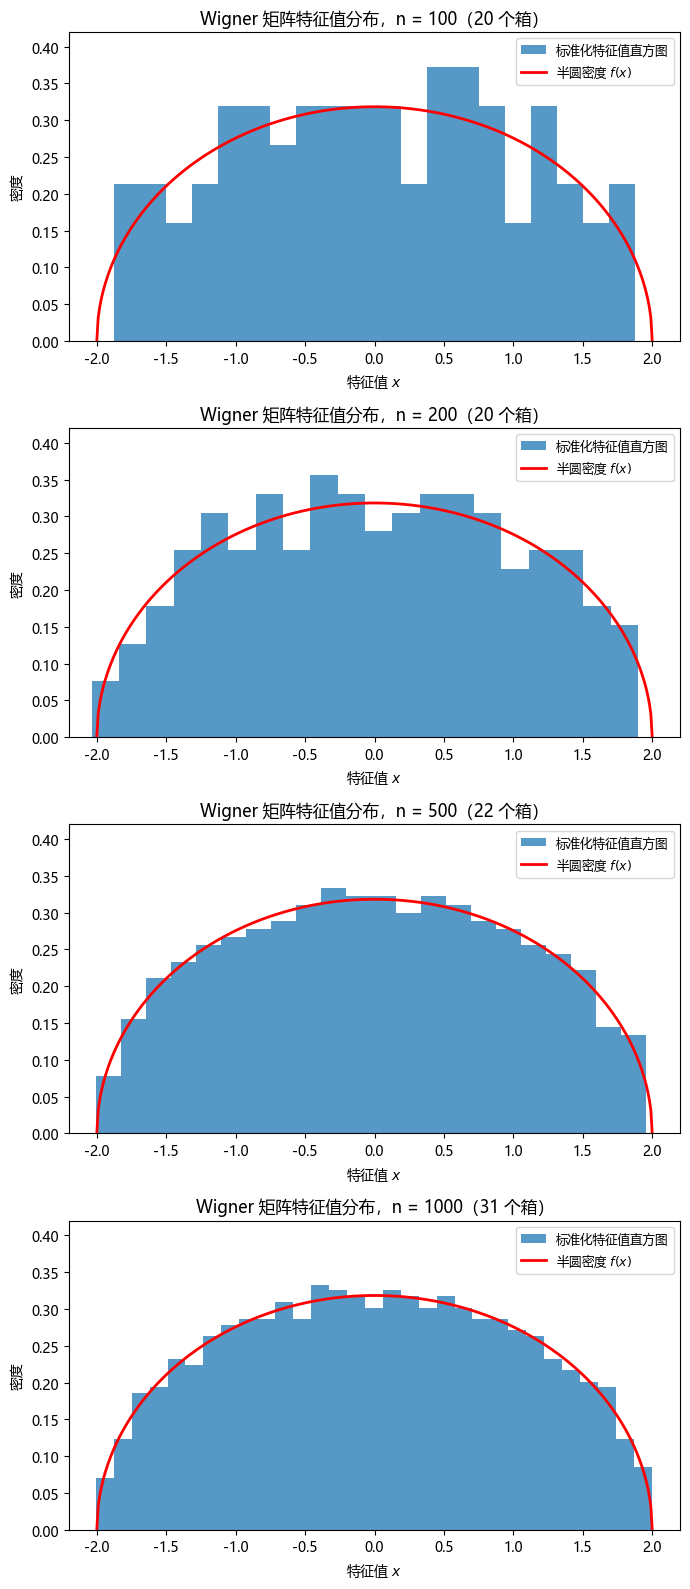

In [8]:
fig, axes = plt.subplots(len(sizes), 1, figsize=(7, 16))

for ax, n in zip(axes, sizes):
    ev = spectra[n]
    # 箱数随样本量增加，避免小 n 时直方图过于锯齿
    nbins = max(20, int(np.sqrt(n)))
    ax.hist(ev, bins=nbins, density=True, color="tab:blue", alpha=0.75,
            label="标准化特征值直方图")
    ax.plot(xs, ys, color="red", lw=2, label=r"半圆密度 $f(x)$")
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(0, 0.42)
    ax.set_title(f"Wigner 矩阵特征值分布，n = {n}（{nbins} 个箱）")
    ax.set_xlabel("特征值 $x$")
    ax.set_ylabel("密度")
    ax.legend(loc="upper right", fontsize=9)

fig.tight_layout()
plt.show()

### 关于 $n$ 的观察

从四张图可以看出：

- $n=100$ 时直方图已经呈现中间高、两侧低、支撑区间约为 $[-2,2]$ 的**钟形/半圆**形状，但轮廓仍有明显起伏，个别箱与曲线偏差较大；
- $n=200$ 时曲线更平滑，与红色半圆密度的偏离缩小；
- $n=500$ 和 $n=1000$ 时，直方图与半圆密度几乎重合。

**结论**：$n\approx 200$ 时轮廓已接近半圆；$n\ge 500$ 后半圆密度能较好地拟合特征值分布，$n=1000$ 时几乎完全重合。也就是说，约 **200–500 阶**就能看出明显的半圆形状。

定量地说，经验分布与半圆分布的偏差随 $n$ 增大而减小（下面用 KS 检验给出 $D$ 统计量）。

In [9]:
def semicircle_cdf(x):
    """半圆密度的累积分布函数（可选任务的 KS 检验用）。"""
    t = np.clip(np.asarray(x, dtype=float), -2.0, 2.0)
    return 0.5 + (t * np.sqrt(4 - t ** 2) / 2 + 2 * np.arcsin(t / 2)) / (2 * np.pi)


print(f"{'n':>6}{'KS D':>10}{'p 值':>14}")
for n in sizes:
    d, p = stats.kstest(spectra[n], semicircle_cdf)
    print(f"{n:>6}{d:>10.4f}{p:>14.4f}")

print()
print("每一档 D 都明显小于临界值，p 值接近 1，不能拒绝“特征值服从半圆分布”的原假设；")
print("同时 D 随 n 单调下降，说明经验分布与半圆分布的差距在缩小。")

     n      KS D           p 值
   100    0.0238        1.0000
   200    0.0141        1.0000
   500    0.0069        1.0000
  1000    0.0032        1.0000

每一档 D 都明显小于临界值，p 值接近 1，不能拒绝“特征值服从半圆分布”的原假设；
同时 D 随 n 单调下降，说明经验分布与半圆分布的差距在缩小。


---

## 二、Conway 的生命游戏

$m\times n$ 棋盘用 NumPy 二维数组表示，活细胞为 $1$、死细胞为 $0$，八邻域（上下左右 + 四个对角）**环绕边界**：

- 活细胞邻居数 $<2$ 或 $>3$ $\Rightarrow$ 死亡；
- 活细胞邻居数为 $2$ 或 $3$ $\Rightarrow$ 存活；
- 死细胞邻居数恰好为 $3$ $\Rightarrow$ 复活；
- 其余死细胞保持死亡。

更新是**同步**的：所有细胞的下一个状态都由**原棋盘**决定。

In [10]:
def is_valid_board(board):
    """判断是否为有效棋盘：二维 ndarray，且元素只为 0 或 1。"""
    arr = np.asarray(board)
    if arr.ndim != 2:
        return False
    return bool(np.all(np.isin(arr, (0, 1))))


samples = {
    "3x3 0/1": np.array([[0, 1, 0], [1, 1, 1], [0, 0, 0]]),
    "一维": np.array([0, 1, 0]),
    "含 2": np.array([[0, 1], [1, 2]]),
    "布尔": np.array([[True, False], [False, True]]),
}
for name, b in samples.items():
    print(f"  {name:<10} -> {is_valid_board(b)}")

  3x3 0/1    -> True
  一维         -> False
  含 2        -> False
  布尔         -> True


In [11]:
def gol_step(board):
    """返回下一代的棋盘；输入无效时抛出 ValueError。"""
    arr = np.asarray(board)
    if not is_valid_board(arr):
        raise ValueError("输入不是有效的生命游戏棋盘（需二维且元素为 0/1）")

    # 八邻域求和，np.roll 天然实现环绕边界
    neighbors = np.zeros(arr.shape, dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(arr, di, axis=0), dj, axis=1)

    alive = arr == 1
    nxt = (alive & ((neighbors == 2) | (neighbors == 3))) | ((~alive) & (neighbors == 3))
    return nxt.astype(int)


# 静物 block 与振荡器 blinker
block = np.array([[1, 1, 0, 0],
                  [1, 1, 0, 0],
                  [0, 0, 0, 0],
                  [0, 0, 0, 0]])
blinker = np.array([[0, 0, 0, 0, 0],
                    [0, 0, 0, 0, 0],
                    [0, 1, 1, 1, 0],
                    [0, 0, 0, 0, 0],
                    [0, 0, 0, 0, 0]])

print("block 是否稳定：", np.array_equal(gol_step(block), block))
print("blinker 周期 2：", np.array_equal(gol_step(gol_step(blinker)), blinker))
print()
print("blinker 下一代：")
print(gol_step(blinker))

try:
    gol_step(np.array([[0, 1], [1, 5]]))
except ValueError as err:
    print("\n无效棋盘 -> ValueError:", err)

block 是否稳定： True
blinker 周期 2： True

blinker 下一代：
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]

无效棋盘 -> ValueError: 输入不是有效的生命游戏棋盘（需二维且元素为 0/1）


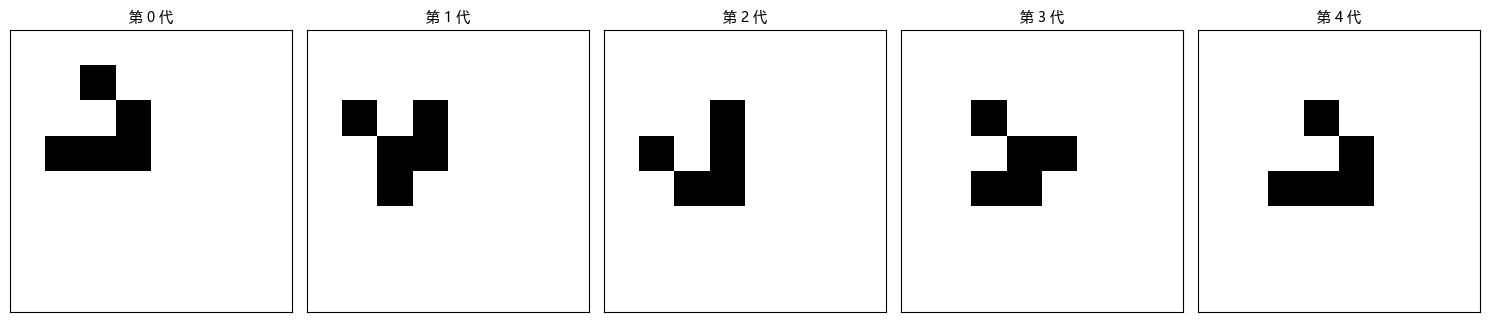

第 4 代 == 第 0 代平移 (1, 1)： True
第 32 代 == 第 0 代（周期 4 × 8 = 32）： True


In [12]:
def draw_gol_board(board):
    """把棋盘画成方格：活细胞黑色、死细胞白色，不显示网格线、轴标签和刻度。"""
    arr = np.asarray(board)
    m, n = arr.shape
    plt.figure(figsize=(n / 2, m / 2))
    plt.imshow(arr, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()


glider = np.zeros((8, 8), dtype=int)
glider[1, 2] = 1
glider[2, 3] = 1
glider[3, 1:4] = 1

boards = [glider]
for _ in range(4):
    boards.append(gol_step(boards[-1]))

fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, b, t in zip(axes, boards, range(5)):
    ax.imshow(b, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"第 {t} 代", fontsize=10)
fig.tight_layout()
plt.show()

# 滑翔机每 4 代整体平移一格；在 8x8 的环绕棋盘上平移 8 次才回到原位
print("第 4 代 == 第 0 代平移 (1, 1)：", np.array_equal(boards[4], np.roll(glider, (1, 1), axis=(0, 1))))

b = glider.copy()
for _ in range(32):
    b = gol_step(b)
print("第 32 代 == 第 0 代（周期 4 × 8 = 32）：", np.array_equal(b, glider))

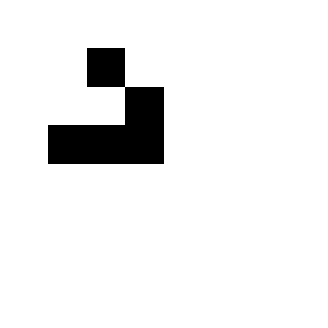

In [13]:
draw_gol_board(glider)

---

## 三、使用 pandas DataFrame

数据文件为 `iris.csv`（150 条记录，第一行为列标题），与本 Notebook 同目录。

In [14]:
from pathlib import Path

DATA = Path("iris.csv")
if not DATA.exists():
    raise FileNotFoundError(f"找不到 {DATA.resolve()}，请把 iris.csv 放到 Notebook 同目录")

df = pd.read_csv(DATA)

print("数据点个数：", len(df))
print("列名：      ", list(df.columns))
print("列数：      ", df.shape[1])
print()
print("各列数据类型：")
print(df.dtypes)
print()
print("花卉种类数：", df["species"].nunique())
print("各品种数量：")
print(df["species"].value_counts())
print()
df.head()

数据点个数： 150
列名：       ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
列数：       5

各列数据类型：
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

花卉种类数： 3
各品种数量：
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64



,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**读入结果说明**

- 数据集共 **150** 个数据点，即 150 朵花；
- 列名为 `sepal_length`、`sepal_width`、`petal_length`、`petal_width`、`species`，分别对应萼片长度、萼片宽度、花瓣长度、花瓣宽度和花卉种类；
- 前四列被识别为浮点型 `float64`，种类列为字符串 `object`；
- 数据中有 **3** 种花卉（setosa / versicolor / virginica），每种各 50 条。

In [15]:
# 第 35 条（索引 34）与第 38 条（索引 37）是已知的录入错误，先看看原值
print("修正前：")
print(df.loc[[34, 37]])

df.loc[34, ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]] = \
    [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37, ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]] = \
    [4.9, 3.6, 1.4, 0.1, "setosa"]

print()
print("修正后：")
print(df.loc[[34, 37]])

修正前：
    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.1  setosa
37           4.9          3.1           1.5          0.1  setosa

修正后：
    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.2  setosa
37           4.9          3.6           1.4          0.1  setosa


第 35 条（索引 34）原来的花瓣宽度为 `0.1`（有误），改为 `0.2`；第 38 条（索引 37）原来的萼片宽度、花瓣长度两项有误，分别改为 `3.6` 和 `1.4`。修改直接在 DataFrame 上原位完成。

In [16]:
# 两个新特征（保留 6 位小数，避免浮点误差写出 6.999999999999999 这类结果）
df["Petal.Ratio"] = (df["petal_length"] / df["petal_width"]).round(6)
df["Sepal.Ratio"] = (df["sepal_length"] / df["sepal_width"]).round(6)

print("新增列：", [c for c in df.columns if c.endswith(".Ratio")])
print()
df.loc[[34, 37]]

新增列： ['Petal.Ratio', 'Sepal.Ratio']



,sepal_length,sepal_width,petal_length,petal_width,species,Petal.Ratio,Sepal.Ratio
34,4.9,3.1,1.5,0.2,setosa,7.5,1.580645
37,4.9,3.6,1.4,0.1,setosa,14.0,1.361111


In [17]:
# 保存修正并扩展后的数据
OUT_CSV = Path("iris_corrected.csv")
df.to_csv(OUT_CSV, index=False)
print("已保存：", OUT_CSV.resolve())

check = pd.read_csv(OUT_CSV)
print("回读形状：", check.shape)
print("列名：    ", list(check.columns))
print()
check.loc[[34, 37]]

已保存： D:\20244080304_李晓月_hw03\iris_corrected.csv
回读形状： (150, 7)
列名：     ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species', 'Petal.Ratio', 'Sepal.Ratio']



,sepal_length,sepal_width,petal_length,petal_width,species,Petal.Ratio,Sepal.Ratio
34,4.9,3.1,1.5,0.2,setosa,7.5,1.580645
37,4.9,3.6,1.4,0.1,setosa,14.0,1.361111


In [18]:
summary = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)

pd.set_option("display.width", 200)
print(summary.round(4))

           Petal.Ratio                               Sepal.Ratio                                
                  mean  median     min   max     std        mean  median     min     max     std
species                                                                                         
setosa          6.9080  7.0000  2.6667  15.0  2.8545      1.4702  1.4631  1.2683  1.9565  0.1187
versicolor      3.2428  3.2404  2.6667   4.1  0.3125      2.1604  2.1613  1.7647  2.8182  0.2287
virginica       2.7807  2.6667  2.1250   4.0  0.4074      2.2305  2.1695  1.8235  2.9615  0.2470


**分组结果说明**

- 三种花的花瓣长宽比差异很大：setosa 平均约 6.9，versicolor 约 3.2，virginica 约 2.8；
- setosa 的 `Petal.Ratio` 离散程度**最大**（std≈2.85），因为它花瓣宽度很小（0.1–0.6），比值被放大且对微小误差敏感；versicolor 最集中（std≈0.31）；
- `Sepal.Ratio` 三种花的均值在 1.5–2.2 之间，组间差异远小于花瓣长宽比，说明**花瓣**的形态更适合区分品种。